What do golfers struggle with, and how does golf instruction address these challenges?

Research objectives
1. Identify recurring themes in online golf instruction using unsupervised machine learning.
2. Determine whether instructional themes differ by golfer skill level and lesson type.
3. Examine whether particular instructional themes are associated with greater golfer recommendations and reported success.
4. Compare the effectiveness and interpretability of different topic modelling approaches.

Option 1: Scraped Dataset

Idea - Look at fit overall for Peter Millar's womens clothing

Expand the web scraping analysis from the midsemester project
1) Extract product specific text (e.g. product descriptions, reviews etc) which is often available after clicking on each product.
2) You are expected to apply an unsupervised machine learning algorithm for text analysis. This can include topic modeling, clustering, or other text analysis methods.


### The Dataset

### Source

### Methodology

### Insights

Set Up
Import packages from external python script and assign global variables

In [28]:
# Import packages from external python script
exec(open("./scripts/import_packages.py").read())

In [ ]:
# Assign global variables
# TODO

BASE_URL = 'https://callawaygolf.com'
PRODUCT_NAME = 'Drivers'
CROSS_XPATH = (
    
)
CATEGORY_XPATH = (
    '//*[@id="radix-:R4r9ul5kq:-trigger-cs6e4314e53bcdb8c4"]/span'
)
PRODUCT_XPATH = (
    '/html/body/div[8]/div/div/div/div[2]/div/div[1]/div/div/div[2]/a/div[1]/div[1]/div/picture/img'
)

Helper Functions

In [42]:
robots = robotparser.RobotFileParser()
robots.set_url(f"{BASE_URL}/robots.txt")
robots.read()

def check_robots(url):
    """Return whether robots.txt permits access to a url"""
    return robots.can_fetch("*", url)

In [43]:
def make_driver():
    return webdriver.Chrome()

In [ ]:
def close_banner():
    """Click the cross for the pop-up advertisement"""
    try:
        button = WebDriverWait(driver, 5).until(
            EC.element_to_be_clickable
        )

In [44]:
def open_item(driver):
    wait = WebDriverWait(driver, 10)
    wait.until(
        EC.element_to_be_clickable((By.XPATH, CATEGORY_XPATH))
    ).click()

    product_link = wait.until(
            EC.element_to_be_clickable((By.XPATH, PRODUCT_XPATH))
        ).click()
    

Start Browser, Open Homepage

In [45]:
driver = make_driver()

#try:
# Open the website
driver.get(BASE_URL)
open_item(driver)

# finally:
#    driver.quit()

ElementClickInterceptedException: Message: element click intercepted: Element <img alt="View: Drivers" data-sentry-element="CMSImage" data-sentry-source-file="tile.tsx" loading="lazy" decoding="auto" data-nimg="fill" class="bg_gray.100" sizes="(max-width: 992px) 50wv, (max-width: 1200px) 33vw, 25vw" srcset="https://images.contentstack.io/v3/assets/bltf7bc8e0c7e024392/blt6e3cf83b6d755618/6969467d7d6f880008c57837/drivers-2026-quantum-max_1.png?auto=webp&amp;width=256&amp;quality=75 256w, https://images.contentstack.io/v3/assets/bltf7bc8e0c7e024392/blt6e3cf83b6d755618/6969467d7d6f880008c57837/drivers-2026-quantum-max_1.png?auto=webp&amp;width=384&amp;quality=75 384w, https://images.contentstack.io/v3/assets/bltf7bc8e0c7e024392/blt6e3cf83b6d755618/6969467d7d6f880008c57837/drivers-2026-quantum-max_1.png?auto=webp&amp;width=640&amp;quality=75 640w, https://images.contentstack.io/v3/assets/bltf7bc8e0c7e024392/blt6e3cf83b6d755618/6969467d7d6f880008c57837/drivers-2026-quantum-max_1.png?auto=web

# NEW VERSION STARTS HERE


In [10]:
# Load and inspect the data
import pandas as pd
import numpy as np
import json
import matplotlib.pyplot as plt
import seaborn as sns

# Load JSON file
with open("./data_raw/golfvotes-lessons.json", "r", encoding="utf-8") as file:
    raw_data = json.load(file)

# Check the strucutre
print("Data type:", type(raw_data))

if isinstance(raw_data, list):
    df = pd.DataFrame(raw_data)

elif isinstance(raw_data, dict):
    print("Top-level keys:", raw_data.keys())

    for key, value in raw_data.items():
        print(key, type(value), len(value) if hasattr(value, "__len__") else "")

df = pd.DataFrame(raw_data["lessons"])
print("\nDataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst five records")
display(df.head())

# Identify columns containing dictionary values
for col in df.columns:
    dict_count = df[col].apply(lambda x: isinstance(x, dict)).sum()

    if dict_count > 0:
        print(f"{col}: {dict_count} dictionary values")

# Inspect the problems field for the first five lessons
for i in range(5):
    print(f"\nLesson {i+1}:")
    print(df.loc[i, "problems"])

# Missing values by column
missing = pd.DataFrame({
    "Missing": df.isna().sum(),
    "Missing (%)": (df.isna().mean() * 100).round(2),
    "Unique Values": [
        df[col].apply(
            lambda x: str(x) if isinstance(x, (dict, list)) else x
        ).nunique()
        for col in df.columns
    ]
})

display(missing.sort_values("Missing (%)", ascending=False))

Data type: <class 'dict'>
Top-level keys: dict_keys(['source', 'generated', 'lessons'])
source <class 'str'> 21
generated <class 'str'> 10
lessons <class 'list'> 2197

Dataset shape: (2197, 11)

Column names:
['id', 'url', 'title', 'coach', 'recommendations', 'fixed_it', 'problems', 'type', 'level', 'summary', 'page']

First five records


,id,url,title,coach,recommendations,fixed_it,problems,type,level,summary,page
0,ASH06DwHaRw,https://www.youtube.com/watch?v=ASH06DwHaRw,The Arm Swing Illusion,Jim Waldron Balance Point Golf,268,49,"{'Over the top': 17, 'Takeaway & backswing': 1...",Explainer,Intermediate,Explains why the arms should not drive the bac...,https://golfvotes.com/watch/ASH06DwHaRw/
1,0IxllCJRKS4,https://www.youtube.com/watch?v=0IxllCJRKS4,Pros vs. Ams | Golf Swing Hip Rotation 🔄,Athletic Motion Golf,134,17,"{'Early extension': 39, 'Setup & posture': 25,...",Explainer,Intermediate,Compares how pros and amateurs rotate the hips...,https://golfvotes.com/watch/0IxllCJRKS4/
2,JXGSFxOf-Iw,https://www.youtube.com/watch?v=JXGSFxOf-Iw,Justin Rose shares his feel vs. real swing drill,PGA Tour,86,9,"{'Early extension': 2, 'How to practice': 19, ...",Drill,Intermediate,Justin Rose shows a feel-versus-real drill tha...,https://golfvotes.com/watch/JXGSFxOf-Iw/
3,p_HZJ2u0TIo,https://www.youtube.com/watch?v=p_HZJ2u0TIo,HOW TO CLEAR YOUR HIPS/PELVIS IN THE GOLF SWIN...,Padraig Harrington,69,11,"{'Swing fundamentals': 4, 'Hip rotation': 48, ...",Explainer,Intermediate,Padraig Harrington explains how to clear the h...,https://golfvotes.com/watch/p_HZJ2u0TIo/
4,iP0sBzIXRtc,https://www.youtube.com/watch?v=iP0sBzIXRtc,Worlds #1 Coach Shares Right Arm Secrets With ...,Danny Maude,65,12,"{'Release & clubface control': 26, 'Swing fund...",Live lesson,Intermediate,A live lesson on how the trail arm and wrist p...,https://golfvotes.com/watch/iP0sBzIXRtc/


problems: 2197 dictionary values

Lesson 1:
{'Over the top': 17, 'Takeaway & backswing': 164, 'Swing fundamentals': 88, 'Hip rotation': 29, 'Transition & downswing': 7, 'Early extension': 4, 'Casting & lag': 2, 'Sway & weight shift': 2, 'Slice': 2, 'Release & clubface control': 2, 'Driver & distance': 2, 'Setup & posture': 3, 'Grip': 4, 'Shanks': 1, 'Mobility & fitness': 1}

Lesson 2:
{'Early extension': 39, 'Setup & posture': 25, 'Transition & downswing': 6, 'Hip rotation': 79, 'Takeaway & backswing': 8, 'Swing fundamentals': 7, 'Sway & weight shift': 16, 'Casting & lag': 3, 'Grip': 1, 'Driver & distance': 1, 'Over the top': 2, 'Shanks': 2, 'Release & clubface control': 1, 'Iron contact': 2, 'Mobility & fitness': 1, 'Slice': 1, 'How to practice': 1}

Lesson 3:
{'Early extension': 2, 'How to practice': 19, 'Transition & downswing': 46, 'Setup & posture': 4, 'Release & clubface control': 4, 'Over the top': 22, 'Takeaway & backswing': 6, 'Swing fundamentals': 5, 'Fat & thin shots': 1, 'C

,Missing,Missing (%),Unique Values
type,21,0.96,8
level,21,0.96,4
summary,21,0.96,2176
id,0,0.00,2197
url,0,0.00,2197
title,0,0.00,2186
coach,0,0.00,375
recommendations,0,0.00,39
fixed_it,0,0.00,16
problems,0,0.00,1758


,Problem,Frequency
1,Takeaway & backswing,824
2,Swing fundamentals,716
4,Transition & downswing,664
16,How to practice,613
3,Hip rotation,609
7,Sway & weight shift,547
9,Release & clubface control,518
11,Setup & posture,498
0,Over the top,441
5,Early extension,336


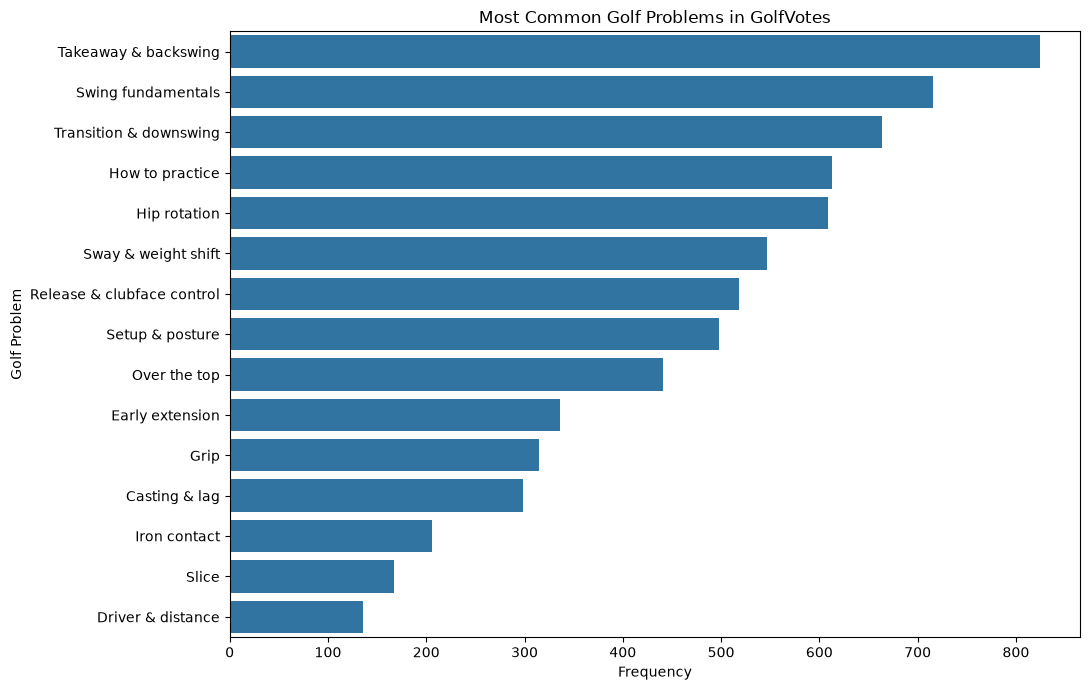

In [12]:
from collections import Counter

# Count how frequently each problem category appears
problem_counts = Counter()

for problems in df["problems"]:
    if isinstance(problems, dict):
        problem_counts.update(problems.keys())

# Convert to DataFrame
problem_summary = pd.DataFrame(
    problem_counts.items(),
    columns=["Problem", "Frequency"]
).sort_values("Frequency", ascending=False)

display(problem_summary)

plt.figure(figsize=(11, 7))

sns.barplot(
    data=problem_summary.head(15),
    x="Frequency",
    y="Problem"
)

plt.title("Most Common Golf Problems in GolfVotes")
plt.xlabel("Frequency")
plt.ylabel("Golf Problem")

plt.tight_layout()
plt.show()

count    2197.00
mean       24.27
std         4.91
min         4.00
10%        18.00
25%        21.00
50%        24.00
75%        28.00
90%        30.00
max        40.00
Name: word_count, dtype: float64

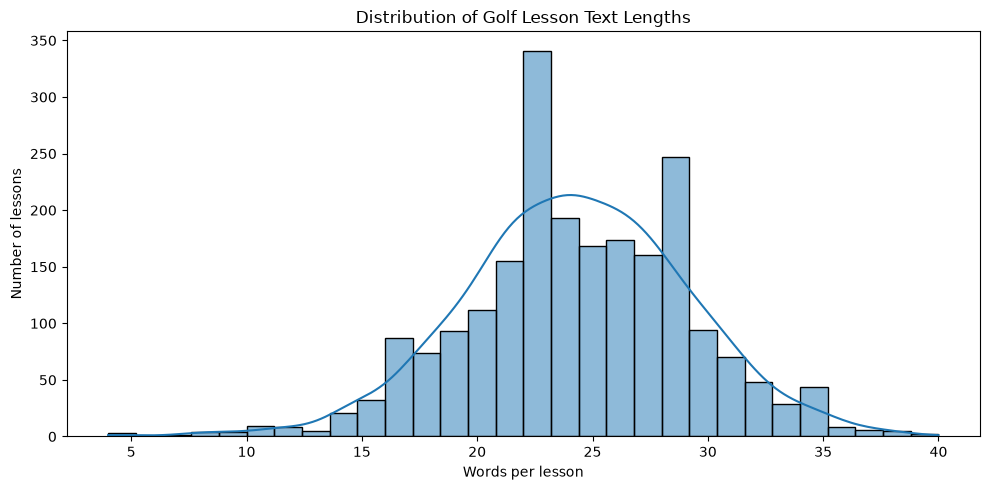

Total lessons: 2197
Non-empty documents: 2197
At least 10 words: 2185
At least 20 words: 1856


In [15]:
# Combine title and summary
df["text"] = (
    df[["title", "summary"]]
    .fillna("")
    .astype(str)
    .agg(" ".join, axis=1)
    .str.strip()
)

# Calculate document length
df["word_count"] = df["text"].str.split().str.len()

# Summary statistics
display(
    df["word_count"].describe(
        percentiles=[0.10, 0.25, 0.50, 0.75, 0.90]
    ).round(2)
)

plt.figure(figsize=(10, 5))

sns.histplot(
    df["word_count"],
    bins=30,
    kde=True
)

plt.title("Distribution of Golf Lesson Text Lengths")
plt.xlabel("Words per lesson")
plt.ylabel("Number of lessons")

plt.tight_layout()
plt.show()

print("Total lessons:", len(df))
print("Non-empty documents:", (df["word_count"] > 0).sum())
print("At least 10 words:", (df["word_count"] >= 10).sum())
print("At least 20 words:", (df["word_count"] >= 20).sum())

In [16]:
for col in ["level", "type"]:

    print(f"\n--- {col.upper()} ---")

    print("Unique categories:", df[col].nunique())

    display(
        df[col]
        .value_counts(dropna=False)
        .to_frame("Number of lessons")
    )


--- LEVEL ---
Unique categories: 4


,Number of lessons
level,
Intermediate,1483
Beginner,306
Advanced,247
All levels,140
None,21



--- TYPE ---
Unique categories: 8


,Number of lessons
type,
Explainer,1012
Drill,652
Quick tip,199
Pro swing,146
Live lesson,123
None,21
Practice plan,18
Fitness,16
Other,10


What are the dominant themes in online golf instruction, and how do they relate to the problems golfers are seeking to solve?

Supporting questions:
1. What instructional themes emerge from golf lesson descriptions?
2. How do these themes differ across skill levels and lesson types?
3. Do the topics identified through machine learning correspond to the most frequently reported golf problems?
4. Are some instructional themes associated with higher recommendation or reported success counts?

In [18]:
for col in ["level", "type"]:
    print(f"\n--- {col.upper()} ---")
    print(df[col].value_counts(dropna=False))

sample = df[["title", "summary", "level", "type"]].sample(
    15, random_state=42
)

for _, row in sample.iterrows():
    print(f"\nTitle: {row['title']}")
    print(f"Summary: {row['summary']}")
    print(f"Level: {row['level']}")
    print(f"Type: {row['type']}")
    print("-" * 80)


--- LEVEL ---
level
Intermediate    1483
Beginner         306
Advanced         247
All levels       140
None              21
Name: count, dtype: int64

--- TYPE ---
type
Explainer        1012
Drill             652
Quick tip         199
Pro swing         146
Live lesson       123
None               21
Practice plan      18
Fitness            16
Other              10
Name: count, dtype: int64

Title: An Easy Way To Create an Inside Out Swing Path
Summary: An easy way to create an inside-out path, with sway fix and a headcover drill.
Level: Intermediate
Type: Drill
--------------------------------------------------------------------------------

Title: It Took Me 35 YEARS to Figure This Out: Johnny Miller
Summary: Johnny Miller's drywall idea for the downswing and hips, which one golfer says adds distance.
Level: Intermediate
Type: Quick tip
--------------------------------------------------------------------------------

Title: Master Your Swing: Step Drill for Lower Body Sequencing wit

In [20]:
# Inspect 15 randomly selected lessons
sample = df[["title", "summary", "level", "type"]].sample(
    15, random_state=42
)

for _, row in sample.iterrows():
    print(f"\nTitle: {row['title']}")
    print(f"Summary: {row['summary']}")
    print(f"Level: {row['level']}")
    print(f"Type: {row['type']}")
    print("-" * 80)

# Check duplicate titles and summaries
print("Duplicate titles:", df["title"].duplicated().sum())

print(
    "Duplicate title-summary combinations:",
    df.duplicated(subset=["title", "summary"]).sum()
)

# Check missing text
print("Missing titles:", df["title"].isna().sum())
print("Missing summaries:", df["summary"].isna().sum())

# Exact duplicate checks
print("Duplicate IDs:", df["id"].duplicated().sum())
print("Duplicate URLs:", df["url"].duplicated().sum())
print(
    "Duplicate titles:",
    df["title"].duplicated().sum()
)
print(
    "Duplicate title-summary combinations:",
    df.duplicated(subset=["title", "summary"]).sum()
)

# Display exact duplicate title-summary records
duplicates = df[
    df.duplicated(
        subset=["title", "summary"],
        keep=False
    )
].sort_values("title")

display(duplicates[["id", "title", "summary"]].head(20))


Title: An Easy Way To Create an Inside Out Swing Path
Summary: An easy way to create an inside-out path, with sway fix and a headcover drill.
Level: Intermediate
Type: Drill
--------------------------------------------------------------------------------

Title: It Took Me 35 YEARS to Figure This Out: Johnny Miller
Summary: Johnny Miller's drywall idea for the downswing and hips, which one golfer says adds distance.
Level: Intermediate
Type: Quick tip
--------------------------------------------------------------------------------

Title: Master Your Swing: Step Drill for Lower Body Sequencing with Dave Phillips! 🏌️‍♂️💥 | Bryn Parry Golf
Summary: A step drill for lower body sequencing with Dave Phillips, building trail foot loading.
Level: Intermediate
Type: Drill
--------------------------------------------------------------------------------

Title: Dr. Kwon’s famous rope drill will improve the rhythm of your golf swing! #golf
Summary: Shows Dr Kwon's rope drill to improve swing rhy

,id,title,summary


In [21]:
# Combine title and summary, handling missing values
df["text"] = (
    df[["title", "summary"]]
    .fillna("")
    .astype(str)
    .agg(" ".join, axis=1)
    .str.strip()
)

# Check that every lesson has usable text
print("Non-empty documents:", df["text"].str.len().gt(0).sum())

# Inspect examples
display(df[["title", "summary", "text"]].head())

Non-empty documents: 2197


,title,summary,text
0,The Arm Swing Illusion,Explains why the arms should not drive the bac...,The Arm Swing Illusion Explains why the arms s...
1,Pros vs. Ams | Golf Swing Hip Rotation 🔄,Compares how pros and amateurs rotate the hips...,Pros vs. Ams | Golf Swing Hip Rotation 🔄 Compa...
2,Justin Rose shares his feel vs. real swing drill,Justin Rose shows a feel-versus-real drill tha...,Justin Rose shares his feel vs. real swing dri...
3,HOW TO CLEAR YOUR HIPS/PELVIS IN THE GOLF SWIN...,Padraig Harrington explains how to clear the h...,HOW TO CLEAR YOUR HIPS/PELVIS IN THE GOLF SWIN...
4,Worlds #1 Coach Shares Right Arm Secrets With ...,A live lesson on how the trail arm and wrist p...,Worlds #1 Coach Shares Right Arm Secrets With ...


In [22]:
# Create modelling dataset
model_df = df.copy()

# Combine title and summary
model_df["text"] = (
    model_df[["title", "summary"]]
    .fillna("")
    .astype(str)
    .agg(" ".join, axis=1)
    .str.strip()
)

# Remove any accidental duplicate whitespace
model_df["text"] = model_df["text"].str.replace(
    r"\s+", " ", regex=True
)

# Check results
print("Number of documents:", len(model_df))
print("Empty documents:", model_df["text"].eq("").sum())
print("Missing summaries:", model_df["summary"].isna().sum())

display(model_df[["title", "summary", "text"]].head())

Number of documents: 2197
Empty documents: 0
Missing summaries: 21


,title,summary,text
0,The Arm Swing Illusion,Explains why the arms should not drive the bac...,The Arm Swing Illusion Explains why the arms s...
1,Pros vs. Ams | Golf Swing Hip Rotation 🔄,Compares how pros and amateurs rotate the hips...,Pros vs. Ams | Golf Swing Hip Rotation 🔄 Compa...
2,Justin Rose shares his feel vs. real swing drill,Justin Rose shows a feel-versus-real drill tha...,Justin Rose shares his feel vs. real swing dri...
3,HOW TO CLEAR YOUR HIPS/PELVIS IN THE GOLF SWIN...,Padraig Harrington explains how to clear the h...,HOW TO CLEAR YOUR HIPS/PELVIS IN THE GOLF SWIN...
4,Worlds #1 Coach Shares Right Arm Secrets With ...,A live lesson on how the trail arm and wrist p...,Worlds #1 Coach Shares Right Arm Secrets With ...


In [23]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    stop_words="english",
    lowercase=True,
    ngram_range=(1, 2),
    min_df=5,
    max_df=0.90,
    sublinear_tf=True
)

X = tfidf.fit_transform(model_df["text"])

print("TF-IDF matrix shape:", X.shape)
print("Vocabulary size:", len(tfidf.get_feature_names_out()))
print("Matrix sparsity:", 1 - X.nnz / (X.shape[0] * X.shape[1]))

TF-IDF matrix shape: (2197, 1403)
Vocabulary size: 1403
Matrix sparsity: 0.9903863591607943


In [24]:
# Get feature names and their average TF-IDF scores
feature_names = tfidf.get_feature_names_out()

mean_tfidf = np.asarray(X.mean(axis=0)).flatten()

top_terms = pd.DataFrame({
    "Term": feature_names,
    "Mean TF-IDF": mean_tfidf
}).sort_values("Mean TF-IDF", ascending=False)

display(top_terms.head(30))

,Term,Mean TF-IDF
1180,swing,0.046592
502,golf,0.044279
265,drill,0.043182
367,explains,0.032762
249,downswing,0.026160
533,golf swing,0.025918
62,backswing,0.023941
442,fix,0.023207
1226,takeaway,0.021027
159,club,0.020121


,Clusters,Inertia,Silhouette Score
0,2,2123.4576,0.0129
1,3,2104.4039,0.0172
2,4,2089.5629,0.0208
3,5,2078.4936,0.0227
4,6,2067.8655,0.0259
5,7,2054.5986,0.0295
6,8,2043.9007,0.0324
7,9,2032.3882,0.0352
8,10,2017.5743,0.0412
9,11,2008.2930,0.0420


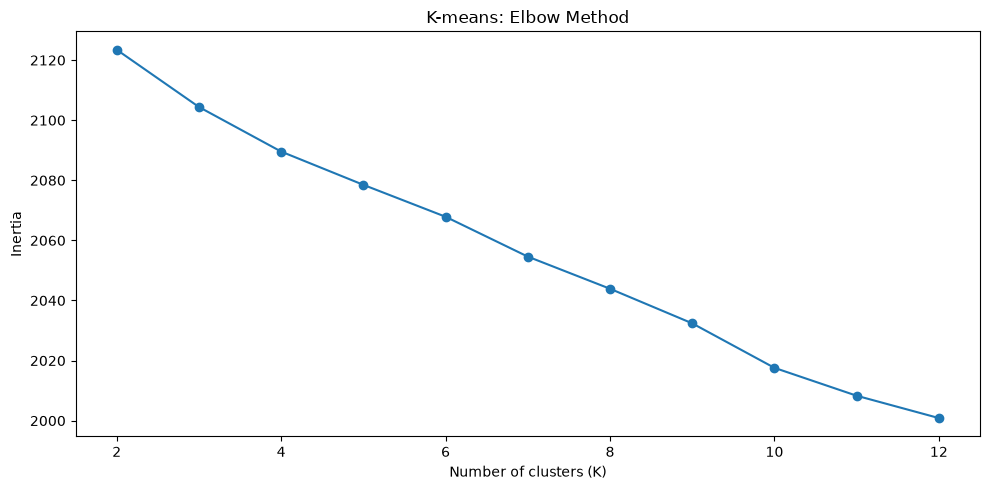

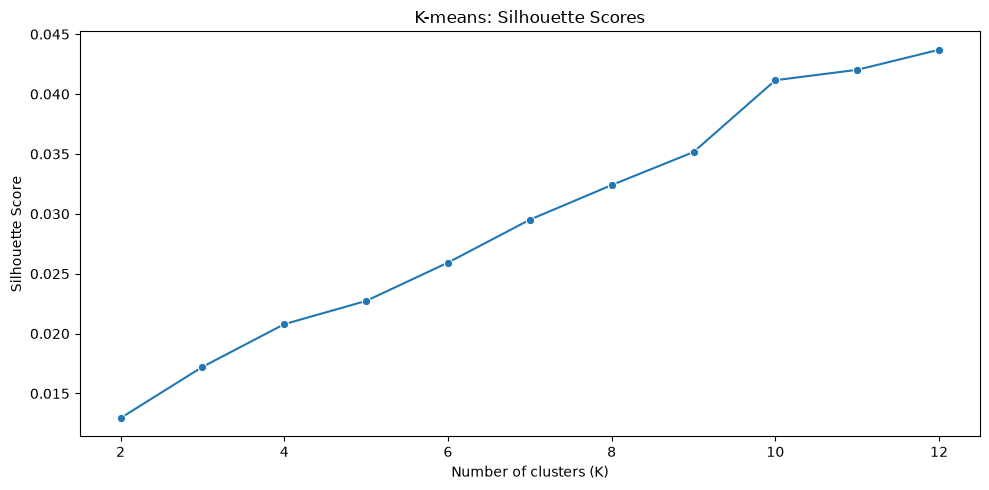

In [27]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

results = []

for k in range(2, 13):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    labels = kmeans.fit_predict(X)

    silhouette = silhouette_score(
        X,
        labels,
        metric="cosine"
    )

    results.append({
        "Clusters": k,
        "Inertia": kmeans.inertia_,
        "Silhouette Score": silhouette
    })

results_df = pd.DataFrame(results)

display(results_df.round(4))

fig, ax1 = plt.subplots(figsize=(10, 5))

ax1.plot(
    results_df["Clusters"],
    results_df["Inertia"],
    marker="o"
)

ax1.set_xlabel("Number of clusters (K)")
ax1.set_ylabel("Inertia")
ax1.set_title("K-means: Elbow Method")

plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))

sns.lineplot(
    data=results_df,
    x="Clusters",
    y="Silhouette Score",
    marker="o"
)

plt.title("K-means: Silhouette Scores")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Silhouette Score")

plt.tight_layout()
plt.show()

In [28]:
from sklearn.cluster import KMeans

feature_names = tfidf.get_feature_names_out()

for k in [8, 10, 12]:

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    labels = model.fit_predict(X)

    model_df[f"cluster_{k}"] = labels

    print(f"\n{'='*60}")
    print(f"K-MEANS WITH {k} CLUSTERS")
    print(f"{'='*60}")

    # Cluster sizes
    print("\nCluster sizes:")
    print(pd.Series(labels).value_counts().sort_index())

    # Top terms per cluster
    for cluster_num, center in enumerate(model.cluster_centers_):

        top_indices = center.argsort()[-10:][::-1]
        top_words = feature_names[top_indices]

        print(f"\nCluster {cluster_num}:")
        print(", ".join(top_words))

    # Representative lesson examples
    print("\nRepresentative lessons:")

    for cluster_num in range(k):

        cluster_docs = model_df[
            model_df[f"cluster_{k}"] == cluster_num
        ]

        print(f"\nCluster {cluster_num}:")
        for title in cluster_docs["title"].head(3):
            print("-", title)


K-MEANS WITH 8 CLUSTERS

Cluster sizes:
0    127
1    357
2    116
3    147
4    128
5     40
6    353
7    929
Name: count, dtype: int64

Cluster 0:
grip, rory, mcilroy, rory mcilroy, golf, club, hand, golf grip, grip golf, golf club

Cluster 1:
downswing, backswing, explains, arm, arms, start, trail, hips, drill, trail arm

Cluster 2:
early extension, extension, early, fix early, fix, hip, hips, drill, golf, explains

Cluster 3:
takeaway, inside, takeaway drill, drill, inside takeaway, perfect, golf, fix, perfect takeaway, swing

Cluster 4:
driver, hit, hit driver, irons, straight, ball, driver straight, swing, driver swing, setup

Cluster 5:
harrington, padraig, padraig harrington, paddy, paddy golf, harrington explains, golf tip, harrington harrington, harrington padraig, tip

Cluster 6:
drill, swing, golf, stop, ball, step, weight, swing drill, shows, step drill

Cluster 7:
swing, golf, golf swing, explains, club, fix, release, drills, ball, including

Representative lessons:

Cl

In [29]:
custom_stopwords = [
    "explains",
    "shows",
    "including",
    "simple"
]

tfidf_clean = TfidfVectorizer(
    stop_words=list(
        set(TfidfVectorizer(
            stop_words="english"
        ).get_stop_words()) | set(custom_stopwords)
    ),
    lowercase=True,
    ngram_range=(1, 2),
    min_df=5,
    max_df=0.90,
    sublinear_tf=True
)

X_clean = tfidf_clean.fit_transform(model_df["text"])

print("Original features:", X.shape[1])
print("Cleaned features:", X_clean.shape[1])

Original features: 1403
Cleaned features: 1323
